# NIRF · Sections 2, 3 & 4 – charts
Self-contained analysis using the attached `nirf_master_final.csv`. All chart calculations are derived from institution-level records; no external `engine` package is required.
Edit the parameters cell and re-run to change category, year or states.

**Revision notes:** one shared colour-blind-safe palette; heatmaps replace the crowded line/stacked charts (Q2.2, Q2.5); range plot (Q3.3); true 1.5×IQR box plot with outliers (Q3.5); sorted horizontal correlation bars with a masked matrix (Q4.3); solid/dotted line styles are explained in every legend; sample sizes appear in titles; an optional interactive plotly scatter (with institution tooltips) is at the end.

> **Validation note:** The notebook contains a self-contained analysis layer and does not require the project `engine` package. A full fresh run requires `nirf_master_final.csv` beside the notebook (or at one of the paths listed in the data-loading cell).

In [1]:

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cbook
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from types import SimpleNamespace
from pathlib import Path

PLOTLY_OK = True
try:
    import plotly
except ImportError:
    PLOTLY_OK = False


# ---- Self-contained data + analysis layer (replaces external engine dependency) ----
from types import SimpleNamespace
from pathlib import Path

DATA_CANDIDATES = [
    Path("nirf_master_final.csv"),
    Path("../nirf_master_final.csv"),
    Path("/mnt/data/nirf_master_final.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find nirf_master_final.csv. Place it beside this notebook "
        "or one directory above it."
    )
df = pd.read_csv(DATA_PATH)
# Some specialised categories (notably Research / Innovation) have no weight_scheme
# metadata in this source. Keep them visible under an explicit, honest label.
df["score_comparison_group"] = df["score_comparison_group"].fillna(
    df["category"].astype(str) + " | weighting not specified"
)

REQUIRED_COLUMNS = {
    "institution_key", "institute_name", "year", "category", "state",
    "rank", "rank_value", "rank_status", "rank_band_label", "rank_midpoint",
    "score", "TLR", "RPC", "GO", "OI", "PR", "is_top100", "is_new_entry",
    "score_comparison_group"
}
missing_cols = REQUIRED_COLUMNS - set(df.columns)
if missing_cols:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_cols)}")

def filter_data(frame, years=None, category=None, require_score=False):
    out = frame.copy()
    if years is not None:
        if np.isscalar(years):
            out = out[out["year"] == int(years)]
        else:
            out = out[out["year"].isin(list(years))]
    if category is not None:
        out = out[out["category"] == category]
    if require_score:
        out = out[pd.to_numeric(out["score"], errors="coerce").notna()]
    return out.copy()

def _empty():
    return pd.DataFrame()

def _top100(frame):
    if "is_top100" in frame:
        return frame[frame["is_top100"].fillna(False).astype(bool)].copy()
    return frame[pd.to_numeric(frame["rank_value"], errors="coerce") <= 100].copy()

def _wrap(result):
    return result.reset_index(drop=True), None

def top_states_top100(frame, category, year):
    d = _top100(filter_data(frame, year, category))
    return _wrap(d.groupby("state").size().rename("institutions_in_top100").reset_index()
                 .sort_values("institutions_in_top100", ascending=False))

def top100_by_state_over_time(frame, category):
    d = _top100(filter_data(frame, category=category))
    return _wrap(d.groupby(["state", "year"]).size().rename("institutions_in_top100").reset_index())

def top100_change_between_years(frame, category, year_a, year_b):
    a = _top100(filter_data(frame, year_a, category)).groupby("state").size()
    b = _top100(filter_data(frame, year_b, category)).groupby("state").size()
    states = sorted(set(a.index) | set(b.index))
    out = pd.DataFrame({"state": states,
                        "change": [int(b.get(s, 0) - a.get(s, 0)) for s in states]})
    return _wrap(out)

def compare_two_states(frame, category, state_a, state_b, exact_only=True):
    d = filter_data(frame, category=category)
    d = d[d["state"].isin([state_a, state_b])].copy()
    rank_col = "rank" if exact_only else "rank_value"
    d[rank_col] = pd.to_numeric(d[rank_col], errors="coerce")
    med = d.groupby(["state", "year"])[rank_col].median().rename("median_rank")
    top = _top100(d).groupby(["state", "year"]).size().rename("top100")
    out = pd.concat([med, top], axis=1).reset_index()
    out["top100"] = out["top100"].fillna(0).astype(int)
    return _wrap(out)

def new_entries_by_state(frame, category):
    d = filter_data(frame, category=category)
    d = d[d["is_new_entry"].fillna(False).astype(bool)]
    return _wrap(d.groupby(["state", "year"]).size().rename("new_entries").reset_index())

def score_distribution(frame, category, year):
    d = filter_data(frame, year, category, True)
    sc = pd.to_numeric(d["score"], errors="coerce").dropna()
    out = pd.DataFrame([{"count": len(sc), "mean": sc.mean(), "median": sc.median(),
                         "min": sc.min(), "max": sc.max()}])
    return _wrap(out)

def _rank_band(value):
    if pd.isna(value): return "Unranked"
    v = int(value)
    if v <= 1: return "1"
    if v <= 5: return "2-5"
    if v <= 10: return "6-10"
    if v <= 20: return "11-20"
    if v <= 50: return "21-50"
    if v <= 100: return "51-100"
    if v <= 150: return "101-150"
    if v <= 200: return "151-200"
    if v <= 250: return "201-250"
    if v <= 300: return "251-300"
    return "301+"

def rank_distribution(frame, category, year, exact_only=False):
    d = filter_data(frame, year, category)
    exact = d[d["rank_status"].eq("exact")].copy()
    band = d[d["rank_status"].eq("band")].copy()
    rows = []
    if not exact.empty:
        exact["rank_bin"] = pd.to_numeric(exact["rank"], errors="coerce").map(_rank_band)
        exact = exact.dropna(subset=["rank_bin"])
        rows.append(exact.groupby("rank_bin").size().rename("institutions").reset_index().assign(rank_type="Exact"))
    if not exact_only and not band.empty:
        band["rank_bin"] = band["rank_band_label"].fillna("Unspecified band").astype(str)
        rows.append(band.groupby("rank_bin").size().rename("institutions").reset_index()
                    .assign(rank_type="Estimated (band midpoint)"))
    out = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(columns=["rank_bin","institutions","rank_type"])
    return _wrap(out)

def score_summary(frame, category, year):
    d = filter_data(frame, year, category, True)
    sc = pd.to_numeric(d["score"], errors="coerce").dropna()
    out = pd.DataFrame([{"count": len(sc), "mean": sc.mean(), "median": sc.median(),
                         "min": sc.min(), "max": sc.max()}])
    return _wrap(out)

def score_summary_over_time(frame, category):
    d = filter_data(frame, category=category)
    rows = []
    for (yr, grp), g in d.groupby(["year", "score_comparison_group"], dropna=False):
        s = pd.to_numeric(g["score"], errors="coerce").dropna()
        if len(s):
            rows.append({"year": int(yr), "score_comparison_group": grp, "mean": s.mean(),
                         "median": s.median(), "min": s.min(), "max": s.max()})
    return _wrap(pd.DataFrame(rows))

def score_range_shares(frame, category, year):
    d = filter_data(frame, year, category, True)
    s = pd.to_numeric(d["score"], errors="coerce").dropna()
    labels = ["0–40", "40–50", "50–60", "60–70", "70–80", "80–90", "90–100"]
    bins = [-np.inf, 40, 50, 60, 70, 80, 90, np.inf]
    cats = pd.cut(s, bins=bins, labels=labels, right=False, include_lowest=True)
    out = cats.value_counts(sort=False).rename("count").reset_index()
    out.columns = ["score_range", "count"]
    out["percent"] = out["count"] / len(s) * 100 if len(s) else 0
    out.attrs.update({"q1": s.quantile(.25) if len(s) else np.nan,
                      "median": s.median() if len(s) else np.nan,
                      "q3": s.quantile(.75) if len(s) else np.nan})
    return out, None

def score_spread_by_category(frame, year):
    d = filter_data(frame, year)
    rows = []
    for grp, g in d.groupby("score_comparison_group", dropna=False):
        s = pd.to_numeric(g["score"], errors="coerce").dropna()
        if len(s):
            q1, q3 = s.quantile([.25, .75])
            rows.append({"score_comparison_group": grp, "count": len(s), "median": s.median(),
                         "q1": q1, "q3": q3, "min": s.min(), "max": s.max(),
                         "iqr": q3-q1, "std": s.std()})
    return _wrap(pd.DataFrame(rows))

def scatter_pair(frame, x, y, category, year):
    if x not in frame.columns or y not in frame.columns:
        raise KeyError(f"Unknown scatter variable: {x if x not in frame.columns else y}")
    d = filter_data(frame, year, category)
    d[x] = pd.to_numeric(d[x], errors="coerce")
    d[y] = pd.to_numeric(d[y], errors="coerce")
    return d.dropna(subset=[x, y]).copy(), None

PARAMS = ["TLR", "RPC", "GO", "OI", "PR"]

def correlation_with_score(frame, category, year):
    d = filter_data(frame, year, category)
    rows = []
    for p in PARAMS:
        pair = d[[p, "score"]].apply(pd.to_numeric, errors="coerce").dropna()
        r = pair[p].corr(pair["score"]) if len(pair) >= 2 and pair[p].nunique()>1 and pair["score"].nunique()>1 else np.nan
        rows.append({"parameter": p, "pearson_r": r, "strongest": False})
    out = pd.DataFrame(rows)
    if out["pearson_r"].notna().any():
        out.loc[out["pearson_r"].abs().idxmax(), "strongest"] = True
    return _wrap(out)

def correlation_matrix(frame, category, year):
    d = filter_data(frame, year, category)
    cols = [c for c in PARAMS + ["score"] if c in d.columns]
    mat = d[cols].apply(pd.to_numeric, errors="coerce").corr()
    out = mat.rename_axis("variable").reset_index()
    return _wrap(out)

def correlation_over_time(frame, category):
    d = filter_data(frame, category=category)
    rows = []
    for (yr, grp), g in d.groupby(["year", "score_comparison_group"], dropna=False):
        for p in PARAMS:
            pair = g[[p, "score"]].apply(pd.to_numeric, errors="coerce").dropna()
            r = pair[p].corr(pair["score"]) if len(pair)>=2 and pair[p].nunique()>1 and pair["score"].nunique()>1 else np.nan
            rows.append({"year": int(yr), "score_comparison_group": grp,
                         "parameter": p, "pearson_r": r})
    return _wrap(pd.DataFrame(rows))

S = SimpleNamespace(
    PARAMS=PARAMS, top_states_top100=top_states_top100,
    top100_by_state_over_time=top100_by_state_over_time,
    top100_change_between_years=top100_change_between_years,
    compare_two_states=compare_two_states, new_entries_by_state=new_entries_by_state,
    score_distribution=score_distribution, rank_distribution=rank_distribution,
    score_summary=score_summary, score_summary_over_time=score_summary_over_time,
    score_range_shares=score_range_shares, score_spread_by_category=score_spread_by_category,
    scatter_pair=scatter_pair, correlation_with_score=correlation_with_score,
    correlation_matrix=correlation_matrix, correlation_over_time=correlation_over_time
)


# ---- Shared, colour-blind-safe palette (Okabe-Ito inspired) ----
PALETTE = {"primary": "#2F6FED", "accent": "#E8590C", "positive": "#0072B2",
           "negative": "#D55E00", "neutral": "#8A8A8A", "highlight": "#CC79A7"}
SERIES = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#000000", "#8A8A8A"]
PARAM_COLORS = {p: SERIES[i % len(SERIES)] for i, p in enumerate(S.PARAMS)}
STAT_STYLE = {"mean": ("#0072B2", "o"), "median": ("#009E73", "s"),
              "min": ("#8A8A8A", "v"), "max": ("#D55E00", "^")}

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.labelsize": 10, "figure.constrained_layout.use": True,
                     "savefig.bbox": "tight"})

# ---- Parameters: edit and re-run ----
CATEGORY, YEAR = "Overall", 2025
YEAR_A, YEAR_B = 2017, 2025
STATE_A, STATE_B = "Karnataka", "Tamil Nadu"
EXACT_ONLY = True
TOP_N_STATES = 10
HEATMAP_STATES = 20
LINE_STATES = 6
N_GAINERS_LOSERS = 10
STANDARDISE_SCATTER = False
PARAMS_SHOWN = None

# ---- Helpers shared by all charts ----
def caption(fig, text):
    fig.supxlabel(text, fontsize=8, color="#555555", x=0.01, ha="left")

def int_years(ax, axis="x"):
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_locator(MaxNLocator(integer=True))

def find_col(frame, candidates):
    return next((c for c in candidates if c in frame.columns), None)

def rank_key(label):
    m = re.search(r"\\d+", str(label))
    return int(m.group()) if m else 10**9

def group_starts(frame):
    if "score_comparison_group" not in frame.columns:
        return []
    g = frame.groupby("score_comparison_group").year.min().sort_values()
    return list(g.iloc[1:].items())

def mark_group_changes(ax, frame):
    for k, (g, y) in enumerate(group_starts(frame)):
        ax.axvline(y - .5, color=PALETTE["neutral"], ls="--", lw=1, zorder=0)
        ax.text(y - .45, 1.0, "comparison group changes" if k == 0 else "",
                transform=ax.get_xaxis_transform(), fontsize=8, color="#555555", va="top")

LINE_STYLE_HANDLES = [
    Line2D([0], [0], color="k", ls="-", marker="o", ms=4, label="Solid = current comparison group"),
    Line2D([0], [0], color="k", ls=":", marker="o", ms=4, label="Dotted = earlier comparison groups")
]
GROUP_NOTE = "Scores before a dashed line use a different peer group / methodology and are not directly comparable."

# Data quality report: keep this visible when the notebook is first run.
print(f"Loaded {len(df):,} institution-category-year records from {DATA_PATH.name}.")
print(f"Years: {df.year.min()}–{df.year.max()} | Categories: {df.category.nunique()} | "
      f"Missing scores: {df.score.isna().sum():,} | Duplicate institution/category/year keys: "
      f"{df.duplicated(['institution_key','category','year']).sum():,}")


Loaded 11,012 institution-category-year records from nirf_master_final.csv.
Years: 2017–2025 | Categories: 16 | Missing scores: 4,089 | Duplicate institution/category/year keys: 0


# 2. Geospatial and regional

### Q2.1  States with the most institutions in the top 100

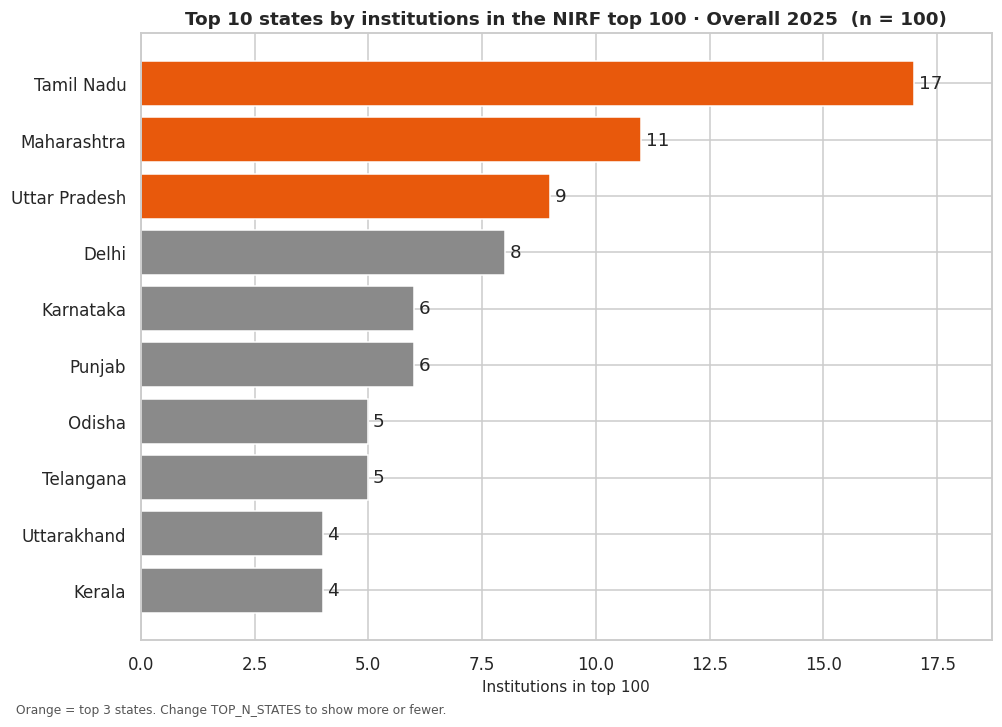

In [2]:
res, _ = S.top_states_top100(df, CATEGORY, YEAR)
r = res.sort_values("institutions_in_top100", ascending=False).head(TOP_N_STATES).iloc[::-1]   # largest at top
colors = [PALETTE["accent"] if i >= len(r) - 3 else PALETTE["neutral"] for i in range(len(r))]   # top 3 highlighted
fig, ax = plt.subplots(figsize=(9, 0.45 * len(r) + 2))
bars = ax.barh(r.state, r.institutions_in_top100, color=colors)
ax.bar_label(bars, fmt="%d", padding=3); ax.margins(x=.1)
ax.set(title=f"Top {len(r)} states by institutions in the NIRF top 100 · {CATEGORY} {YEAR}  (n = {int(res.institutions_in_top100.sum())})",
       xlabel="Institutions in top 100", ylabel="")
caption(fig, "Orange = top 3 states. Change TOP_N_STATES to show more or fewer.")
plt.show()

### Q2.2  How the geographic distribution of top institutions changes over time

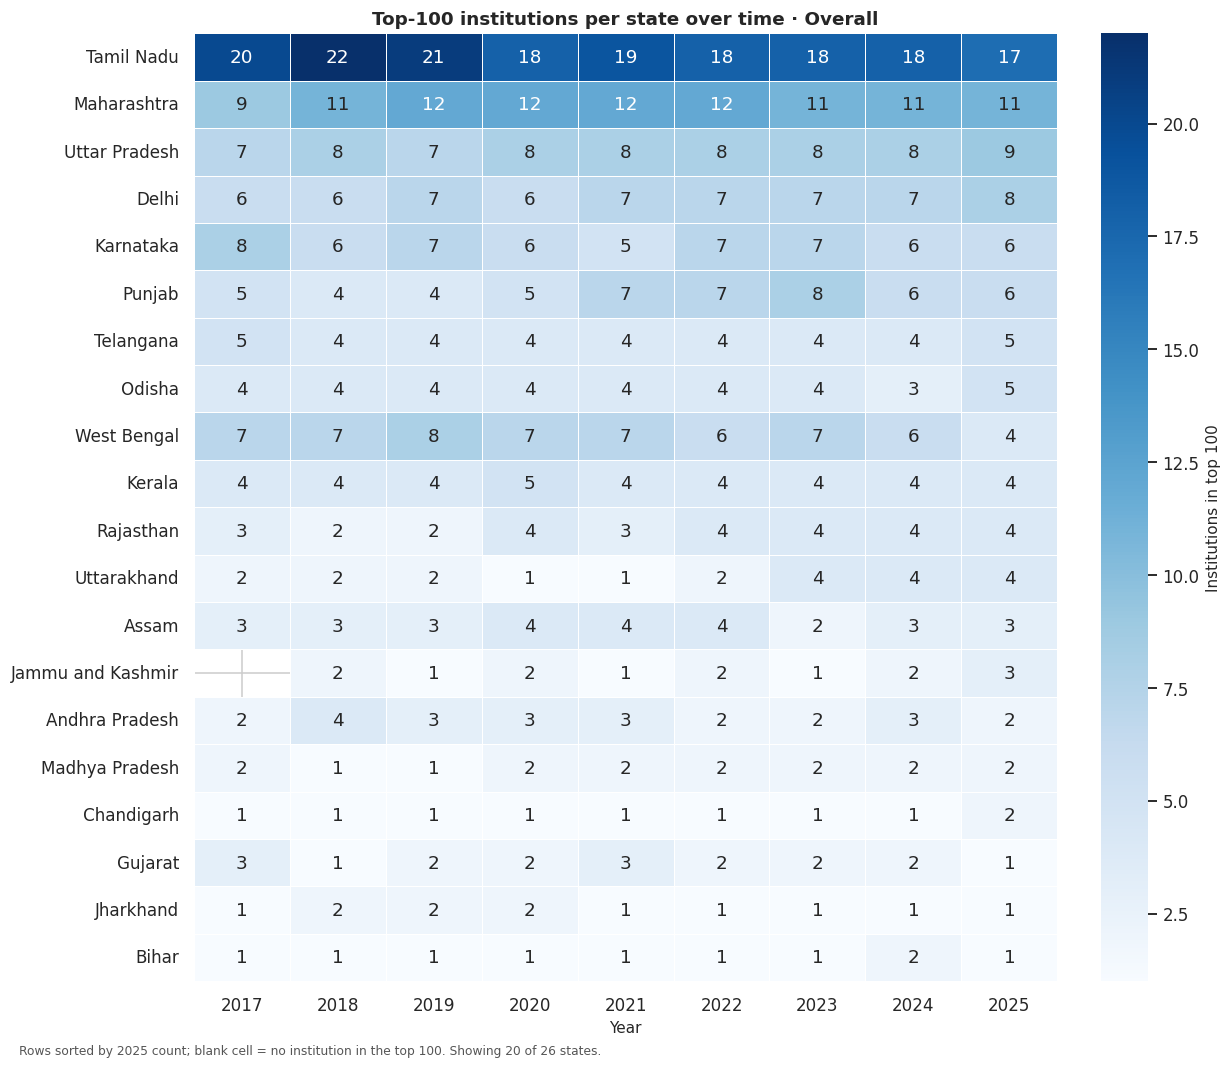

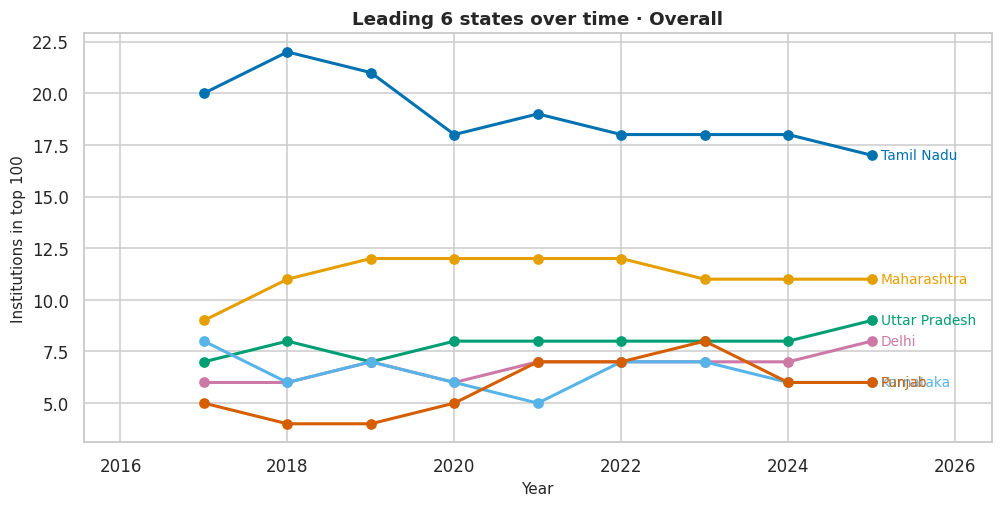

In [3]:
res, _ = S.top100_by_state_over_time(df, CATEGORY)
pv = (res.pivot_table(index="state", columns="year", values="institutions_in_top100", aggfunc="sum", fill_value=0)
         .sort_index(axis=1))
pv = pv[pv.sum(axis=1) > 0]
latest = pv.columns[-1]
pv = pv.assign(_total=pv.sum(axis=1)).sort_values([latest, "_total"], ascending=False).drop(columns="_total")
hm = pv.head(HEATMAP_STATES).round().astype(int)

# Primary view: state x year heatmap, rows sorted by latest-year count, blank = no institution in the top 100
fig, ax = plt.subplots(figsize=(max(7, 0.9 * hm.shape[1] + 3), 0.38 * len(hm) + 2))
sns.heatmap(hm, mask=(hm == 0), annot=True, fmt="d", cmap="Blues", linewidths=.5, linecolor="white",
            cbar_kws={"label": "Institutions in top 100"}, ax=ax)
ax.set(title=f"Top-100 institutions per state over time · {CATEGORY}", xlabel="Year", ylabel="")
caption(fig, f"Rows sorted by {latest} count; blank cell = no institution in the top 100. Showing {len(hm)} of {len(pv)} states.")
plt.show()

# Supporting view: only the leading states, labelled at the line ends instead of a legend
top = hm.index[:LINE_STATES]
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, s in enumerate(top):
    ax.plot(pv.columns, pv.loc[s], marker="o", color=SERIES[i % len(SERIES)], lw=2)
    ax.annotate(s, (pv.columns[-1], pv.loc[s].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=9, color=SERIES[i % len(SERIES)], annotation_clip=False)
ax.margins(x=.18); int_years(ax)
ax.set(title=f"Leading {len(top)} states over time · {CATEGORY}", xlabel="Year", ylabel="Institutions in top 100")
plt.show()

### Q2.3  States that improved (or lost) top-100 representation

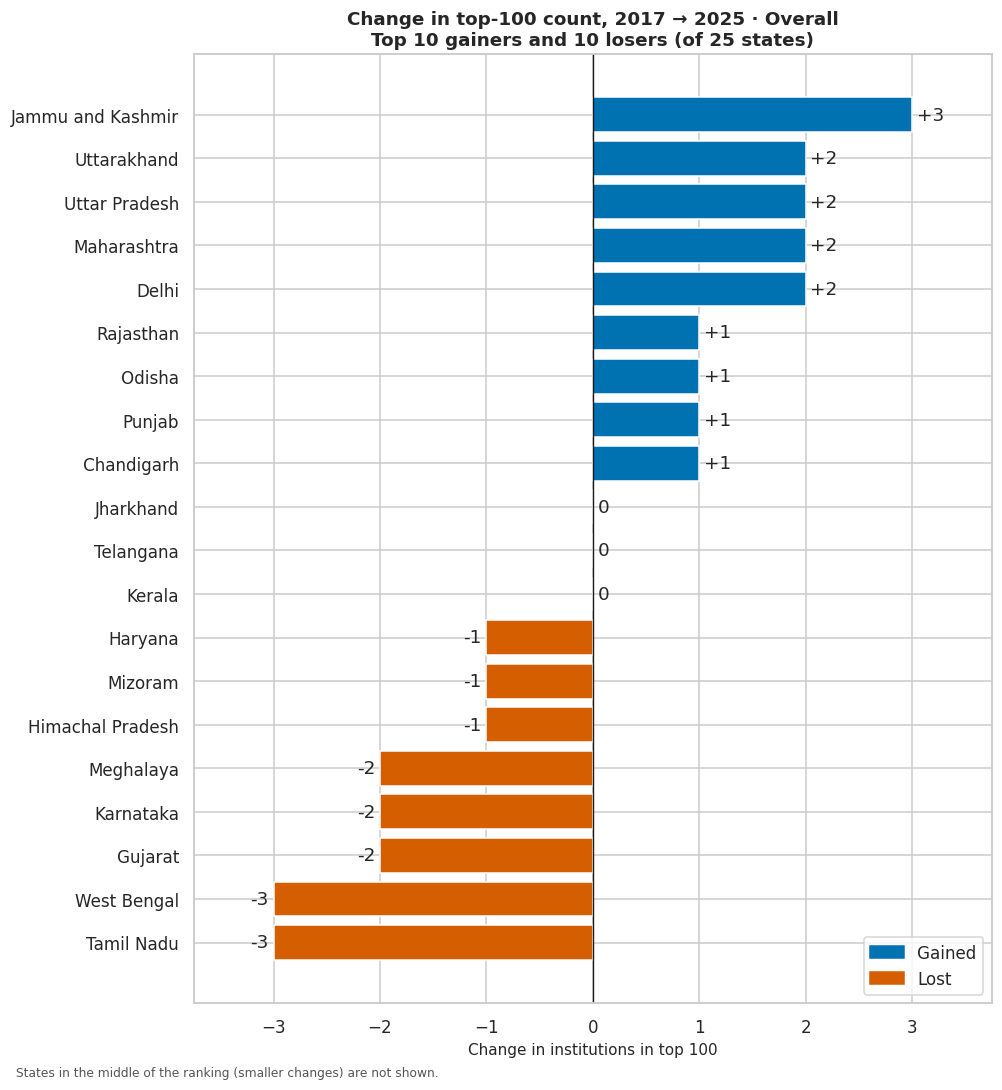

In [4]:
res, _ = S.top100_change_between_years(df, CATEGORY, YEAR_A, YEAR_B)
res = res.sort_values("change", ascending=False)
n = N_GAINERS_LOSERS
truncated = len(res) > 2 * n
v = (pd.concat([res.head(n), res.tail(n)]) if truncated else res).sort_values("change")
colors = np.where(v.change > 0, PALETTE["positive"], np.where(v.change < 0, PALETTE["negative"], PALETTE["neutral"]))
fig, ax = plt.subplots(figsize=(9, 0.38 * len(v) + 2.2))
bars = ax.barh(v.state, v.change, color=colors)
ax.bar_label(bars, labels=[f"{int(c):+d}" if c else "0" for c in v.change], padding=3)
ax.axvline(0, color="k", lw=.9)
lim = max(1, v.change.abs().max()); ax.set_xlim(-lim * 1.25, lim * 1.25)
ttl = f"Change in top-100 count, {YEAR_A} → {YEAR_B} · {CATEGORY}"
if truncated: ttl += f"\nTop {n} gainers and {n} losers (of {len(res)} states)"
ax.set(title=ttl, xlabel="Change in institutions in top 100", ylabel="")
ax.legend(handles=[Patch(color=PALETTE["positive"], label="Gained"), Patch(color=PALETTE["negative"], label="Lost")], loc="lower right")
if truncated: caption(fig, "States in the middle of the ranking (smaller changes) are not shown.")
plt.show()

### Q2.4  Karnataka vs Tamil Nadu

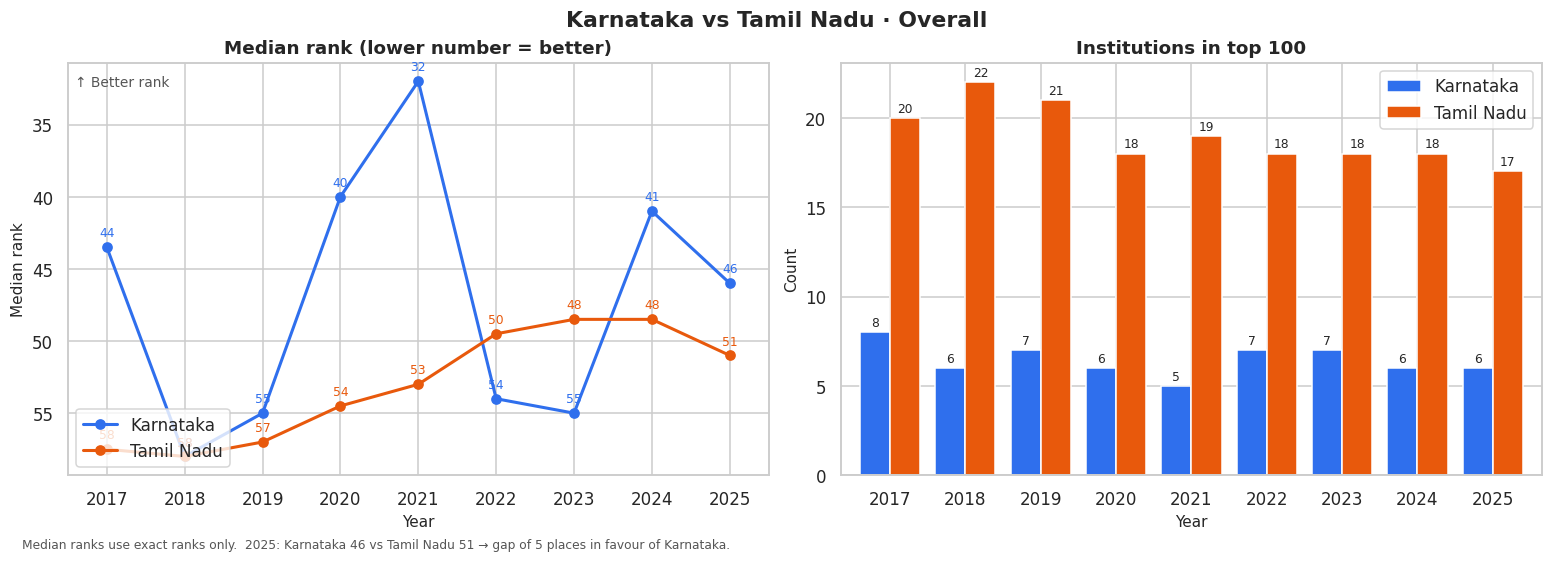

In [5]:
res, _ = S.compare_two_states(df, CATEGORY, STATE_A, STATE_B, exact_only=EXACT_ONLY)
STATE_COLORS = {STATE_A: PALETTE["primary"], STATE_B: PALETTE["accent"]}   # same colours in both panels
years = sorted(res.year.unique())
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for s, g in res.groupby("state"):
    g = g.sort_values("year"); c = STATE_COLORS.get(s, PALETTE["neutral"])
    axs[0].plot(g.year, g.median_rank, marker="o", lw=2, color=c, label=s)
    for x_, y_ in zip(g.year, g.median_rank):
        if pd.notna(y_): axs[0].annotate(f"{y_:.0f}", (x_, y_), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8, color=c)
axs[0].invert_yaxis(); axs[0].legend(loc="lower left")
axs[0].text(.01, .97, "↑ Better rank", transform=axs[0].transAxes, va="top", fontsize=9, color="#555555")
axs[0].set_xlim(min(years) - .5, max(years) + .5); int_years(axs[0])
axs[0].set(title="Median rank (lower number = better)", xlabel="Year", ylabel="Median rank")

pv_top = res.pivot(index="year", columns="state", values="top100").reindex(years).fillna(0)
cols = [c for c in (STATE_A, STATE_B) if c in pv_top.columns]
pv_top[cols].plot.bar(ax=axs[1], rot=0, color=[STATE_COLORS[c] for c in cols], width=.8)
for cont in axs[1].containers: axs[1].bar_label(cont, fmt="%d", fontsize=8, padding=2)
axs[1].set(title="Institutions in top 100", xlabel="Year", ylabel="Count"); axs[1].legend(title="")
fig.suptitle(f"{STATE_A} vs {STATE_B} · {CATEGORY}", fontweight="bold")

note = "Median ranks use exact ranks only." if EXACT_ONLY else "Median ranks include estimated band midpoints (not exact ranks)."
pm = res.pivot(index="year", columns="state", values="median_rank")
if {STATE_A, STATE_B} <= set(pm.columns) and pm[[STATE_A, STATE_B]].dropna().shape[0]:
    ly = pm[[STATE_A, STATE_B]].dropna().index[-1]; a_, b_ = pm.loc[ly, STATE_A], pm.loc[ly, STATE_B]
    lead = STATE_A if a_ < b_ else STATE_B
    note += f"  {ly}: {STATE_A} {a_:.0f} vs {STATE_B} {b_:.0f} → gap of {abs(a_ - b_):.0f} places in favour of {lead}."
caption(fig, note)
plt.show()

### Q2.5  States with the most newly appearing institutions

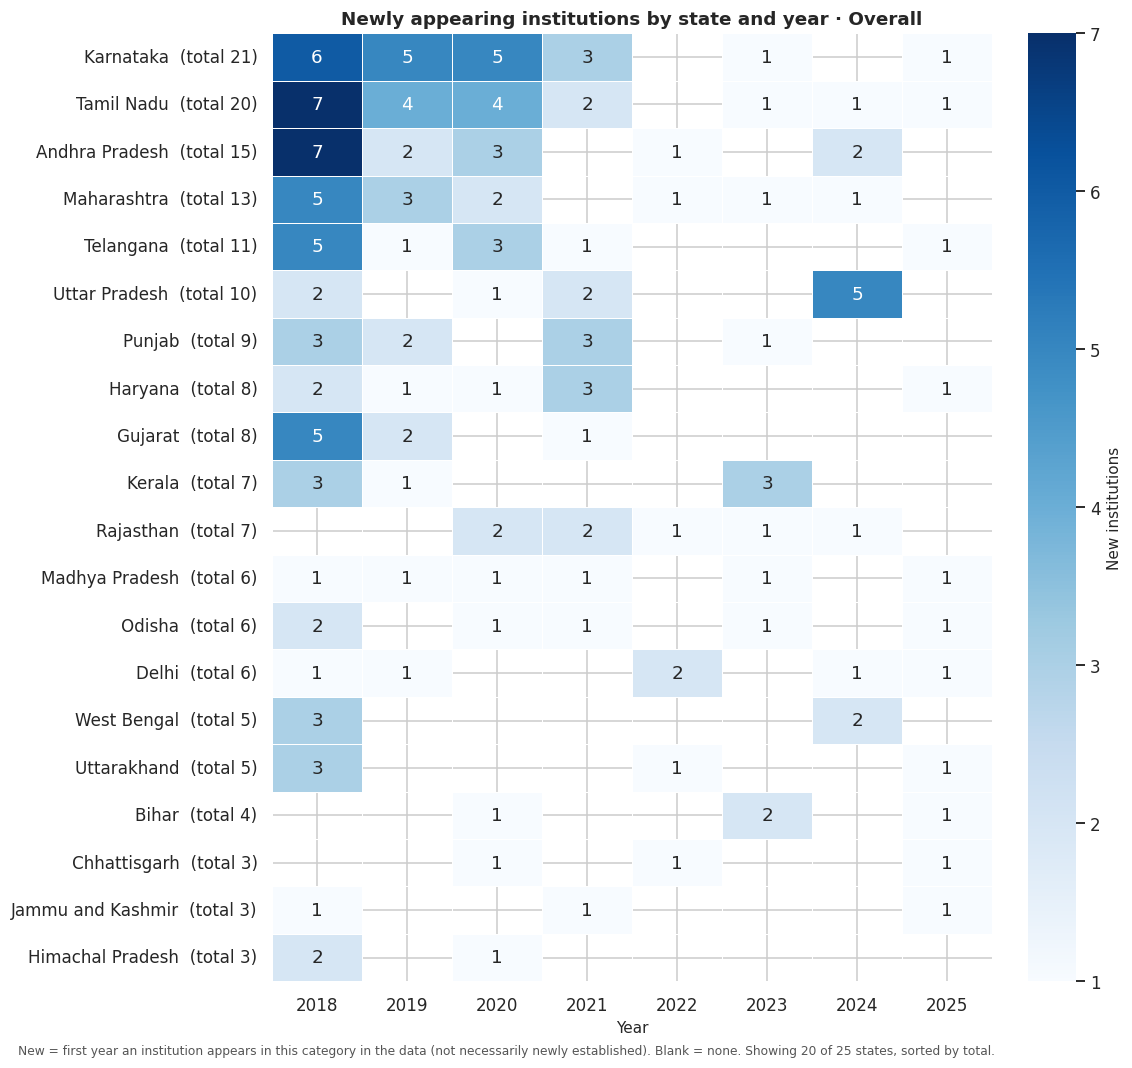

Note: 2018 is the first year in the data, so most of its 'new' entries are just the starting list.


In [6]:
res, _ = S.new_entries_by_state(df, CATEGORY)
pv = res.pivot_table(index="state", columns="year", values="new_entries", aggfunc="sum", fill_value=0).sort_index(axis=1)
tot = pv.sum(axis=1).sort_values(ascending=False)
hm = pv.loc[tot.head(HEATMAP_STATES).index].round().astype(int)
hm.index = [f"{s}  (total {int(tot[s])})" for s in hm.index]
fig, ax = plt.subplots(figsize=(max(7, 0.9 * hm.shape[1] + 3), 0.38 * len(hm) + 2))
sns.heatmap(hm, mask=(hm == 0), annot=True, fmt="d", cmap="Blues", linewidths=.5, linecolor="white",
            cbar_kws={"label": "New institutions"}, ax=ax)
ax.set(title=f"Newly appearing institutions by state and year · {CATEGORY}", xlabel="Year", ylabel="")
caption(fig, "New = first year an institution appears in this category in the data (not necessarily newly established). "
             f"Blank = none. Showing {len(hm)} of {len(pv)} states, sorted by total.")
plt.show()
if pv.shape[1] > 2 and pv.iloc[:, 0].sum() > 2 * pv.iloc[:, 1:].sum().median():
    print(f"Note: {pv.columns[0]} is the first year in the data, so most of its 'new' entries are just the starting list.")

# 3. Univariate analysis

### Q3.1  Distribution of NIRF scores

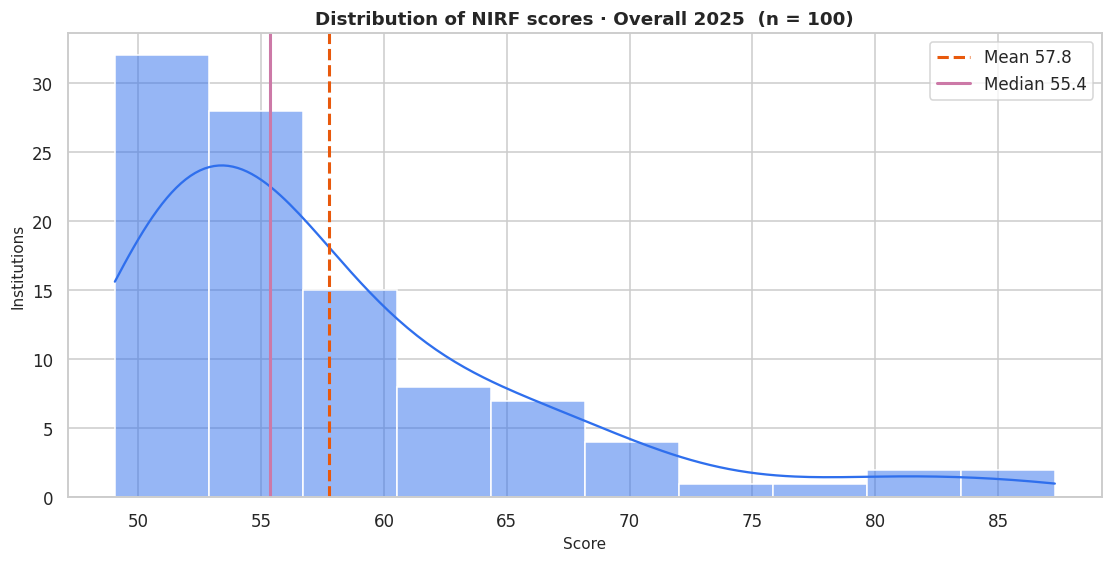

 count    mean  median   min   max
   100 57.7612   55.35 49.04 87.31


In [7]:
res, _ = S.score_distribution(df, CATEGORY, YEAR)
sc = filter_data(df, years=YEAR, category=CATEGORY, require_score=True).score.dropna()
if len(sc) < 2:
    print("Not enough scored institutions to draw a distribution.")
else:
    bins = int(np.clip(np.sqrt(len(sc)), 8, 25))
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.histplot(sc, bins=bins, kde=True, color=PALETTE["primary"], edgecolor="white", ax=ax)
    ax.axvline(sc.mean(), color=PALETTE["accent"], ls="--", lw=2, label=f"Mean {sc.mean():.1f}")
    ax.axvline(sc.median(), color=PALETTE["highlight"], ls="-", lw=2, label=f"Median {sc.median():.1f}")
    ax.set(title=f"Distribution of NIRF scores · {CATEGORY} {YEAR}  (n = {len(sc)})", xlabel="Score", ylabel="Institutions")
    ax.legend(); plt.show()
print(res.to_string(index=False))

### Q3.2  Distribution of ranks

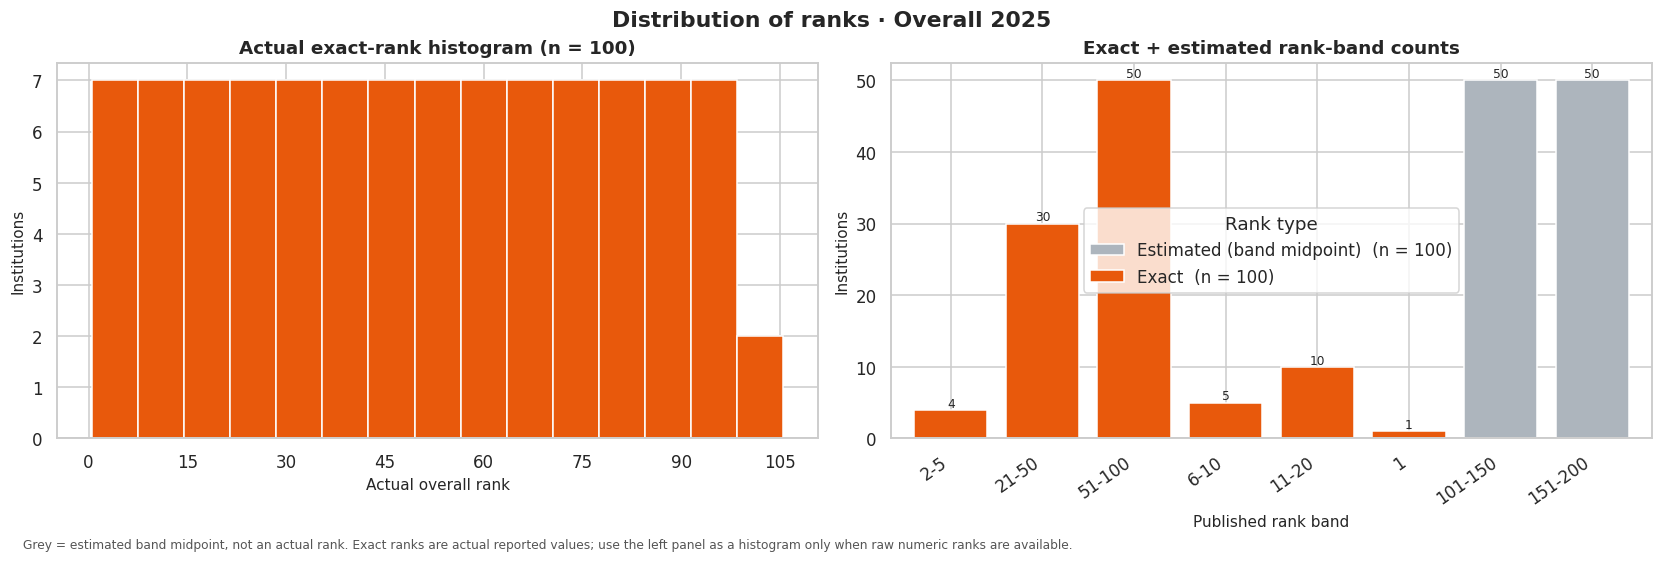

In [8]:
r_exact, _ = S.rank_distribution(df, CATEGORY, year=YEAR, exact_only=True)
r_all, _ = S.rank_distribution(df, CATEGORY, year=YEAR, exact_only=False)
order = sorted(set(r_all.rank_bin) | set(r_exact.rank_bin), key=rank_key)  # numeric band order

# Prefer a histogram of institution-level exact ranks. The engine's rank-bin
# summary alone cannot reconstruct individual rank values, so detect a raw field.
RANK_COL_CANDIDATES = ["overall_rank", "rank", "rank_value", "rank_number", "rank_exact"]
rank_col = find_col(df, RANK_COL_CANDIDATES)
raw_year = filter_data(df, years=YEAR, category=CATEGORY)
exact_rows = raw_year[raw_year["rank_status"].eq("exact")] if "rank_status" in raw_year.columns else raw_year
exact_values = pd.to_numeric(exact_rows[rank_col], errors="coerce").dropna() if rank_col else pd.Series(dtype=float)

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
if len(exact_values):
    lo, hi = int(exact_values.min()), int(exact_values.max())
    bin_width = max(1, int(np.ceil((hi - lo + 1) / 15)))
    edges = np.arange(lo - .5, hi + bin_width + .5, bin_width)
    axs[0].hist(exact_values, bins=edges, color=PALETTE["accent"], edgecolor="white")
    axs[0].set(title=f"Actual exact-rank histogram (n = {len(exact_values)})",
               xlabel="Actual overall rank", ylabel="Institutions")
    axs[0].xaxis.set_major_locator(MaxNLocator(integer=True))
else:
    # Safe fallback: rank-bin summaries do not contain enough information to
    # reconstruct individual exact ranks. Label this as a grouped distribution.
    ex = r_exact.groupby("rank_bin").institutions.sum().reindex(order, fill_value=0)
    bars = axs[0].bar(ex.index.astype(str), ex.values, color=PALETTE["accent"])
    axs[0].bar_label(bars, fmt="%d", padding=2, fontsize=8)
    axs[0].set(title=f"Exact-rank counts by published rank band (n = {int(ex.sum())})",
               xlabel="Published rank band", ylabel="Institutions")
    axs[0].tick_params(axis="x", rotation=35)
    print("No institution-level numeric exact-rank column was found. Showing grouped exact-rank counts; this is not a raw-rank histogram.")

pv = (r_all.pivot_table(index="rank_bin", columns="rank_type", values="institutions", aggfunc="sum", fill_value=0)
          .reindex(order, fill_value=0))
cmap = {"Exact": PALETTE["accent"], "Estimated (band midpoint)": "#ADB5BD"}
pv.plot.bar(stacked=True, ax=axs[1], color=[cmap.get(c, PALETTE["neutral"]) for c in pv.columns], width=.8)
for i, t in enumerate(pv.sum(axis=1)):
    axs[1].text(i, t, int(t), ha="center", va="bottom", fontsize=8)
axs[1].legend([f"{c}  (n = {int(pv[c].sum())})" for c in pv.columns], title="Rank type")
axs[1].set(title="Exact + estimated rank-band counts", xlabel="Published rank band", ylabel="Institutions")
for t in axs[1].get_xticklabels():
    t.set_rotation(35); t.set_ha("right")
fig.suptitle(f"Distribution of ranks · {CATEGORY} {YEAR}", fontweight="bold")
caption(fig, "Grey = estimated band midpoint, not an actual rank. Exact ranks are actual reported values; use the left panel as a histogram only when raw numeric ranks are available.")
plt.show()


### Q3.3  Average, median, minimum and maximum score

 count    mean  median   min   max
   100 57.7612   55.35 49.04 87.31


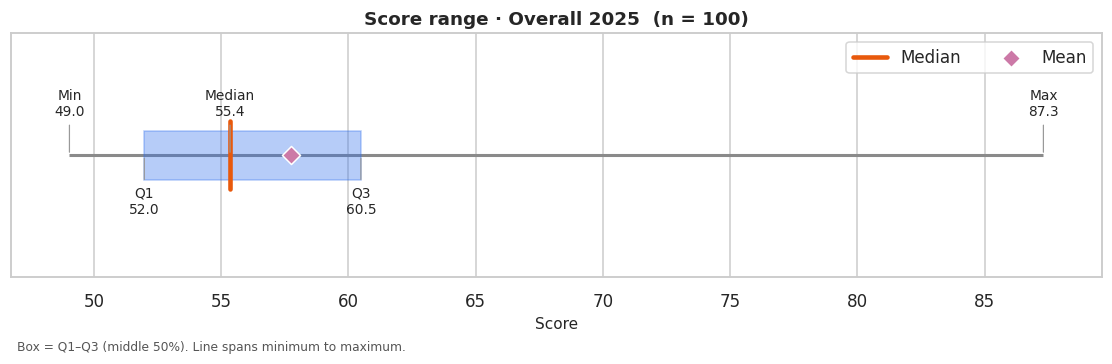

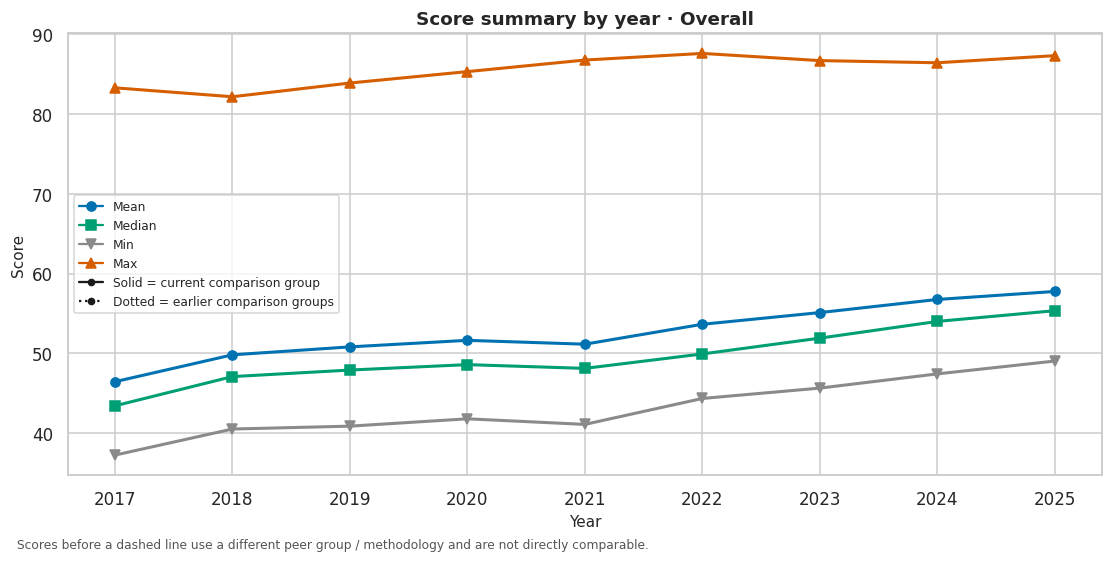

In [9]:
res, _ = S.score_summary(df, CATEGORY, YEAR)
print(res.to_string(index=False))
sc = filter_data(df, years=YEAR, category=CATEGORY, require_score=True).score.dropna()
if len(sc) < 2:
    print("Not enough scored institutions for a range plot.")
else:
    q = sc.quantile([0, .25, .5, .75, 1]).values; mean = sc.mean()
    fig, ax = plt.subplots(figsize=(10, 3.2))
    ax.hlines(0, q[0], q[4], color=PALETTE["neutral"], lw=2, zorder=1)
    ax.barh(0, q[3] - q[1], left=q[1], height=.4, color=PALETTE["primary"], alpha=.35, edgecolor=PALETTE["primary"], zorder=2)
    ax.plot([q[2], q[2]], [-.28, .28], color=PALETTE["accent"], lw=3, label="Median", zorder=3)
    ax.scatter([mean], [0], marker="D", s=70, color=PALETTE["highlight"], edgecolor="white", zorder=4, label="Mean")
    for i, (nm, val) in enumerate(zip(["Min", "Q1", "Median", "Q3", "Max"], q)):
        ax.annotate(f"{nm}\n{val:.1f}", (val, 0), xytext=(0, 26 if i % 2 == 0 else -38), textcoords="offset points",
                    ha="center", fontsize=9, arrowprops=dict(arrowstyle="-", color="#999999", lw=.8))
    pad = (q[4] - q[0]) * .06 or 1
    ax.set(xlim=(q[0] - pad, q[4] + pad), ylim=(-1, 1), xlabel="Score", title=f"Score range · {CATEGORY} {YEAR}  (n = {len(sc)})")
    ax.set_yticks([]); ax.legend(loc="upper right", ncol=2); ax.grid(axis="y", visible=False)
    caption(fig, "Box = Q1–Q3 (middle 50%). Line spans minimum to maximum.")
    plt.show()

res2, _ = S.score_summary_over_time(df, CATEGORY)
last = res2.score_comparison_group.iloc[-1]
fig, ax = plt.subplots(figsize=(10, 5))
for g, gd in res2.groupby("score_comparison_group"):
    gd = gd.sort_values("year")
    for st, (c, mk) in STAT_STYLE.items():
        ax.plot(gd.year, gd[st], marker=mk, color=c, ls="-" if g == last else ":", lw=2)
mark_group_changes(ax, res2); int_years(ax)
stat_handles = [Line2D([0], [0], color=c, marker=mk, ls="-", label=st.title()) for st, (c, mk) in STAT_STYLE.items()]
ax.legend(handles=stat_handles + LINE_STYLE_HANDLES, fontsize=8, loc="best")
ax.set(title=f"Score summary by year · {CATEGORY}", xlabel="Year", ylabel="Score")
caption(fig, GROUP_NOTE)
plt.show()

### Q3.4  Share of institutions by score range

Engine groups: max deviation from 25% = 32.0 pts → NOT equal-sized: these are fixed score ranges, not quartiles.


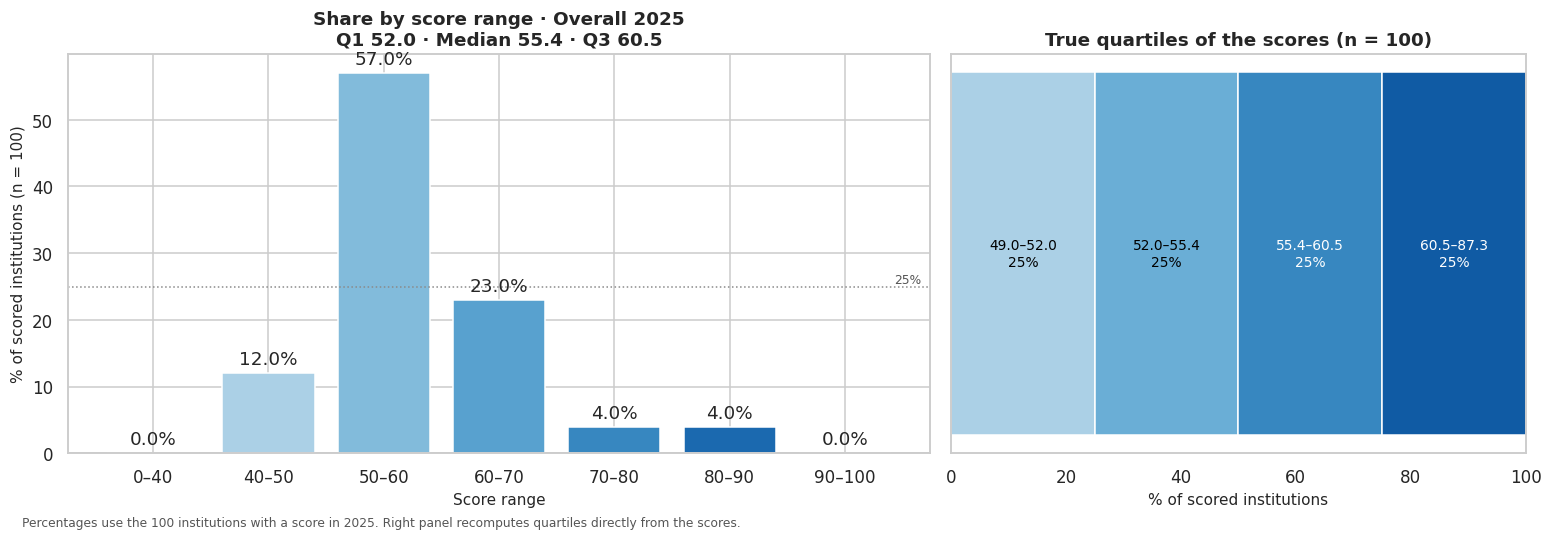

In [10]:
res, _ = S.score_range_shares(df, CATEGORY, YEAR)
a = res.attrs
sc = filter_data(df, years=YEAR, category=CATEGORY, require_score=True).score.dropna(); n = len(sc)
dev = (res.percent - 25).abs().max()
print(f"Engine groups: max deviation from 25% = {dev:.1f} pts → " +
      ("approximately equal-sized (quartile-like)." if dev <= 3 else "NOT equal-sized: these are fixed score ranges, not quartiles."))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [3, 2]})
shades = sns.color_palette("Blues", len(res) + 1)[1:]
bars = axs[0].bar(res.score_range.astype(str), res.percent, color=shades)
axs[0].bar_label(bars, labels=[f"{v:.1f}%" for v in res.percent], padding=3)
axs[0].axhline(25, color=PALETTE["neutral"], ls=":", lw=1); axs[0].text(.99, 25.5, "25%", transform=axs[0].get_yaxis_transform(), ha="right", fontsize=8, color="#555555")
axs[0].set(title=f"Share by score range · {CATEGORY} {YEAR}\nQ1 {a['q1']:.1f} · Median {a['median']:.1f} · Q3 {a['q3']:.1f}",
           xlabel="Score range", ylabel=f"% of scored institutions (n = {n})")

edges = np.unique(sc.quantile([0, .25, .5, .75, 1]).values)      # duplicate boundaries merged
if len(edges) >= 3:
    sh = pd.cut(sc, edges, include_lowest=True).value_counts(sort=False) / n * 100
    shades2 = sns.color_palette("Blues", len(sh) + 1)[1:]; left = 0
    for i, (iv, val) in enumerate(sh.items()):
        axs[1].barh(0, val, left=left, color=shades2[i], edgecolor="white")
        axs[1].text(left + val / 2, 0, f"{iv.left:.1f}–{iv.right:.1f}\n{val:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if i >= len(sh) / 2 else "black"); left += val
    axs[1].set(xlim=(0, 100), xlabel="% of scored institutions")
else:
    axs[1].text(.5, .5, "Scores too similar to form quartiles", ha="center", transform=axs[1].transAxes)
axs[1].set_yticks([]); axs[1].grid(False)
axs[1].set_title(f"True quartiles of the scores (n = {n})" + ("" if len(edges) == 5 else "\n(tied boundaries merged)"))
caption(fig, f"Percentages use the {n} institutions with a score in {YEAR}. Right panel recomputes quartiles directly from the scores.")
plt.show()

### Q3.5  Spread of scores across categories

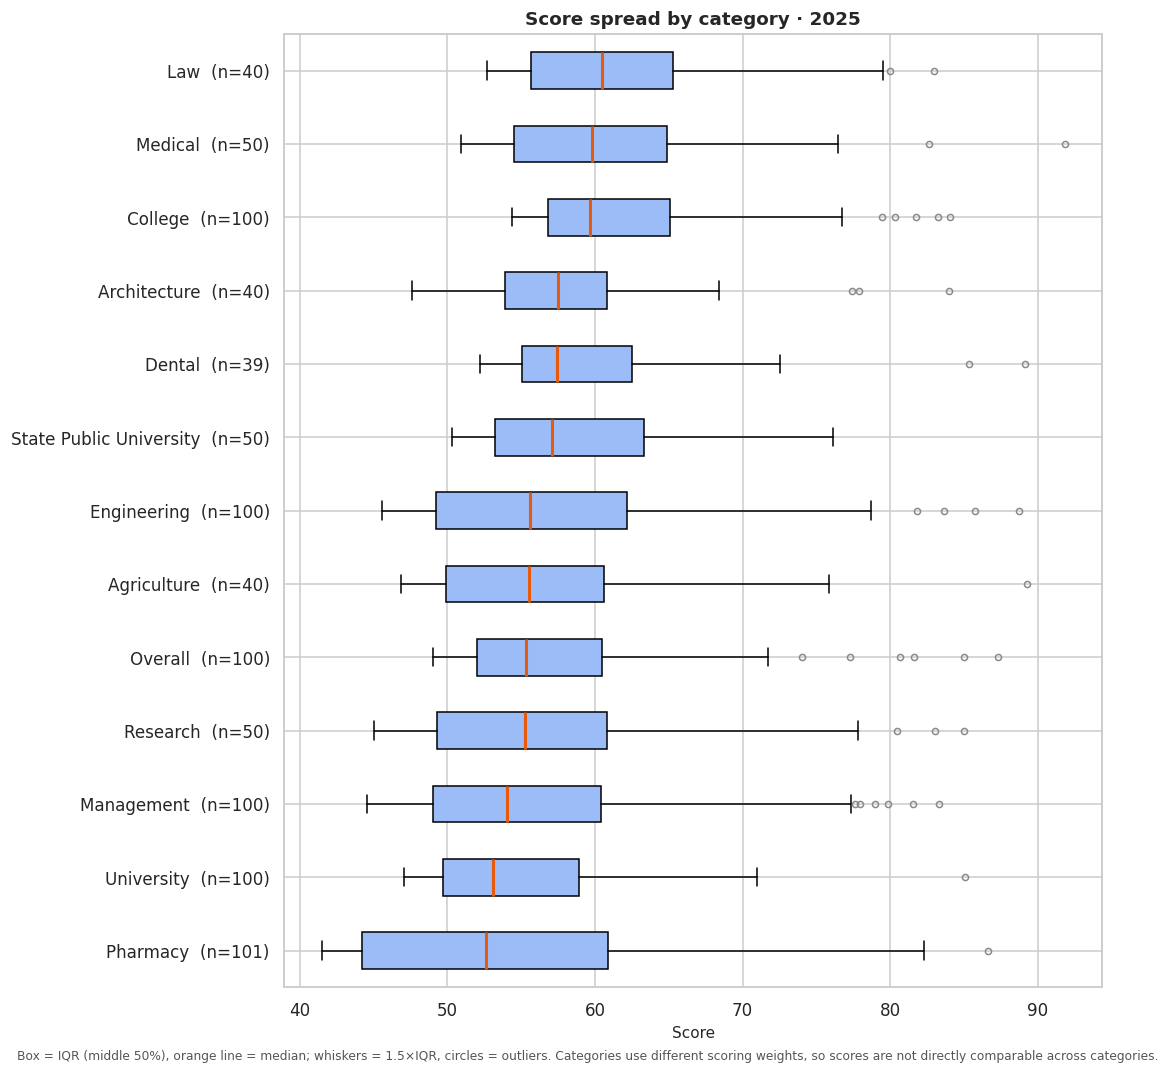

               category  count  median     iqr       std
                    Law     40  60.475  9.6300  8.543369
                Medical     50  59.810 10.3075  8.452902
                College    100  59.660  8.2225  7.330577
           Architecture     40  57.465  6.9375  8.064828
                 Dental     39  57.420  7.4700  8.350549
State Public University     50  57.100 10.1350  6.555067
            Engineering    100  55.595 12.9350  9.396976
            Agriculture     40  55.495 10.7525  9.184938
                Overall    100  55.350  8.5100  8.175946
               Research     50  55.250 11.5125 10.128324
             Management    100  54.055 11.3775  9.308214
             University    100  53.070  9.2425  6.933476
               Pharmacy    101  52.600 16.6500 10.888734

Full category labels (with scoring weights):
 - Law | 40/15/25/10/10
 - Medical | 30/30/20/10/10
 - College | 40/15/25/10/10
 - Architecture | 40/20/20/10/10
 - Dental | 30/30/20/10/10
 - State Public 

[None, None, None, None, None, None, None, None, None, None, None, None, None]

In [11]:
res, _ = S.score_spread_by_category(df, YEAR)
GRP = "score_comparison_group"
short = lambda s: str(s).split("|")[0].strip()          # scoring weights moved out of the axis labels
raw_ok = all(c in df.columns for c in ["year", GRP, "score"])
stats, full = [], []
if raw_ok:                                               # conventional box plot: 1.5×IQR whiskers + outliers
    raw = df[(df.year == YEAR) & df.score.notna()]
    for g, vals in raw.groupby(GRP).score:
        st = cbook.boxplot_stats(vals.values, whis=1.5)[0]
        st["label"] = f"{short(g)}  (n={len(vals)})"; stats.append(st); full.append(g)
    whisk = "whiskers = 1.5×IQR, circles = outliers"
else:                                                    # fallback: summary table only (min–max whiskers, no outliers)
    print("Raw institution-level scores are unavailable. Summary-only fallback uses min–max whiskers; outliers cannot be identified from summary statistics.")
    for _, r_ in res.iterrows():
        stats.append(dict(label=f"{short(r_[GRP])}  (n={int(r_['count'])})", med=r_["median"], q1=r_.q1, q3=r_.q3,
                          whislo=r_["min"], whishi=r_["max"], fliers=[])); full.append(r_[GRP])
    whisk = "whiskers = min–max"
idx = sorted(range(len(stats)), key=lambda i: stats[i]["med"])          # ascending → highest median drawn at top
stats = [stats[i] for i in idx]; full = [full[i] for i in idx]
fig, ax = plt.subplots(figsize=(10, 0.55 * len(stats) + 2.5))
ax.bxp(stats, vert=False, showfliers=True, patch_artist=True, boxprops=dict(facecolor="#9BBCF7"),
       medianprops=dict(color=PALETTE["accent"], lw=2),
       flierprops=dict(marker="o", markerfacecolor="none", markeredgecolor=PALETTE["neutral"], markersize=4))
ax.set(title=f"Score spread by category · {YEAR}", xlabel="Score")
caption(fig, f"Box = IQR (middle 50%), orange line = median; {whisk}. Categories use different scoring weights, so scores are not directly comparable across categories.")
plt.show()
tbl = res.assign(category=res[GRP].map(short)).sort_values("median", ascending=False)       # same order as the chart (top → bottom)
print(tbl[["category", "count", "median", "iqr", "std"]].to_string(index=False))
print("\nFull category labels (with scoring weights):"); [print(" -", g) for g in full[::-1]]

# 4. Bivariate analysis and correlation

In [ ]:
NAME_COLS = ["institute_name", "institution", "institution_name", "name", "Name", "institute", "college"]

def draw_scatter(x, y, standardise=None, n_label=3):
    standardise = STANDARDISE_SCATTER if standardise is None else standardise
    res, _ = S.scatter_pair(df, x, y, CATEGORY, YEAR)
    d = res.dropna(subset=[x, y]).copy()
    if len(d) < 3 or d[x].nunique() < 2 or d[y].nunique() < 2:          # safeguard: too few / constant values
        print(f"Not enough variation to plot {x} vs {y} (n = {len(d)})."); return res
    xv, yv = d[x].astype(float), d[y].astype(float)
    if standardise: xv, yv = (xv - xv.mean()) / xv.std(ddof=0), (yv - yv.mean()) / yv.std(ddof=0)
    m, c = np.polyfit(xv, yv, 1); r = np.corrcoef(xv, yv)[0, 1]
    resid = yv - (m * xv + c)
    nm = find_col(d, NAME_COLS)
    top = yv.nlargest(n_label).index; out = resid.abs().nlargest(n_label).index
    fig, ax = plt.subplots(figsize=(8, 6.4))
    ax.scatter(xv, yv, alpha=.55, s=40, color=PALETTE["primary"], edgecolor="white", lw=.4, label="Institution")
    ax.scatter(xv[top], yv[top], s=70, color=PALETTE["highlight"], edgecolor="k", lw=.6, zorder=4, label=f"Top {n_label} by {y}")
    ax.scatter(xv[out], yv[out], s=130, facecolor="none", edgecolor=PALETTE["accent"], lw=1.6, zorder=4, label=f"Largest {n_label} residuals")
    xs = np.array([xv.min(), xv.max()])
    ax.plot(xs, c + m * xs, color=PALETTE["accent"], lw=2, label=f"Trend (slope {m:.2f})")
    if nm:
        for i in top.union(out):
            ax.annotate(str(d.loc[i, nm])[:28], (xv[i], yv[i]), xytext=(6, 5), textcoords="offset points", fontsize=8)
    z = " (z-score)" if standardise else ""
    ax.set(title=f"{x} vs {y} · {CATEGORY} {YEAR}\nPearson r = {r:.2f}   R² = {r**2:.2f}   slope = {m:.2f}   n = {len(d)}",
           xlabel=x + z, ylabel=y + z)
    ax.legend(loc="lower right", fontsize=8)
    extra = "  TLR and RPC have different maximum marks - set STANDARDISE_SCATTER = True to compare relative deviations." if {x, y} == {"TLR", "RPC"} else ""
    caption(fig, "Association, not causation." + extra)
    plt.show()
    return res


def interactive_scatter(x, y, show_trend=True):
    """Create a reusable Plotly scatter with institution-name hover labels."""
    if not PLOTLY_OK:
        print("Plotly is not installed; install it with `pip install plotly` to use interactive scatter plots.")
        return None

    import plotly.graph_objects as go

    res, _ = S.scatter_pair(df, x, y, CATEGORY, YEAR)
    d = res.copy()
    d[x] = pd.to_numeric(d[x], errors="coerce")
    d[y] = pd.to_numeric(d[y], errors="coerce")
    d = d.dropna(subset=[x, y])

    if len(d) < 3 or d[x].nunique() < 2 or d[y].nunique() < 2:
        print(f"Not enough non-constant paired observations for {x} vs {y} (n = {len(d)}).")
        return None

    nm = find_col(d, NAME_COLS)
    names = d[nm].fillna("Unknown institution").astype(str) if nm else d.index.astype(str)
    xv, yv = d[x].astype(float), d[y].astype(float)
    r = float(np.corrcoef(xv, yv)[0, 1])
    fig = go.Figure()
    fig.add_scatter(
        x=xv, y=yv, mode="markers", text=names,
        marker=dict(size=8, opacity=.65, color=PALETTE["primary"]),
        hovertemplate=f"<b>%{{text}}</b><br>{x}: %{{x:.2f}}<br>{y}: %{{y:.2f}}<extra></extra>",
        name="Institution"
    )

    subtitle = f"Pearson r = {r:.3f} · n = {len(d)}"
    if show_trend:
        slope, intercept = np.polyfit(xv, yv, 1)
        xs = np.array([xv.min(), xv.max()])
        fig.add_scatter(
            x=xs, y=intercept + slope * xs, mode="lines",
            line=dict(color=PALETTE["accent"], width=2),
            name=f"Trend (slope {slope:.3f})"
        )
        subtitle += f" · R² = {r**2:.3f} · slope = {slope:.3f}"

    fig.update_layout(
        title=f"{x} vs {y} · {CATEGORY} {YEAR}<br><sup>{subtitle}</sup>",
        xaxis_title=x, yaxis_title=y, template="plotly_white",
        hovermode="closest", margin=dict(l=60, r=30, t=85, b=60),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
    )
    return fig


### Q4.1  RPC vs overall score

In [ ]:
_ = draw_scatter("RPC", "score")
interactive_fig = interactive_scatter("RPC", "score")
if interactive_fig is not None:
    interactive_fig.show()


### Q4.2  Perception (PR) vs overall score

In [ ]:
_ = draw_scatter("PR", "score")
interactive_fig = interactive_scatter("PR", "score")
if interactive_fig is not None:
    interactive_fig.show()


### Q4.3  Which parameter correlates most with overall score?

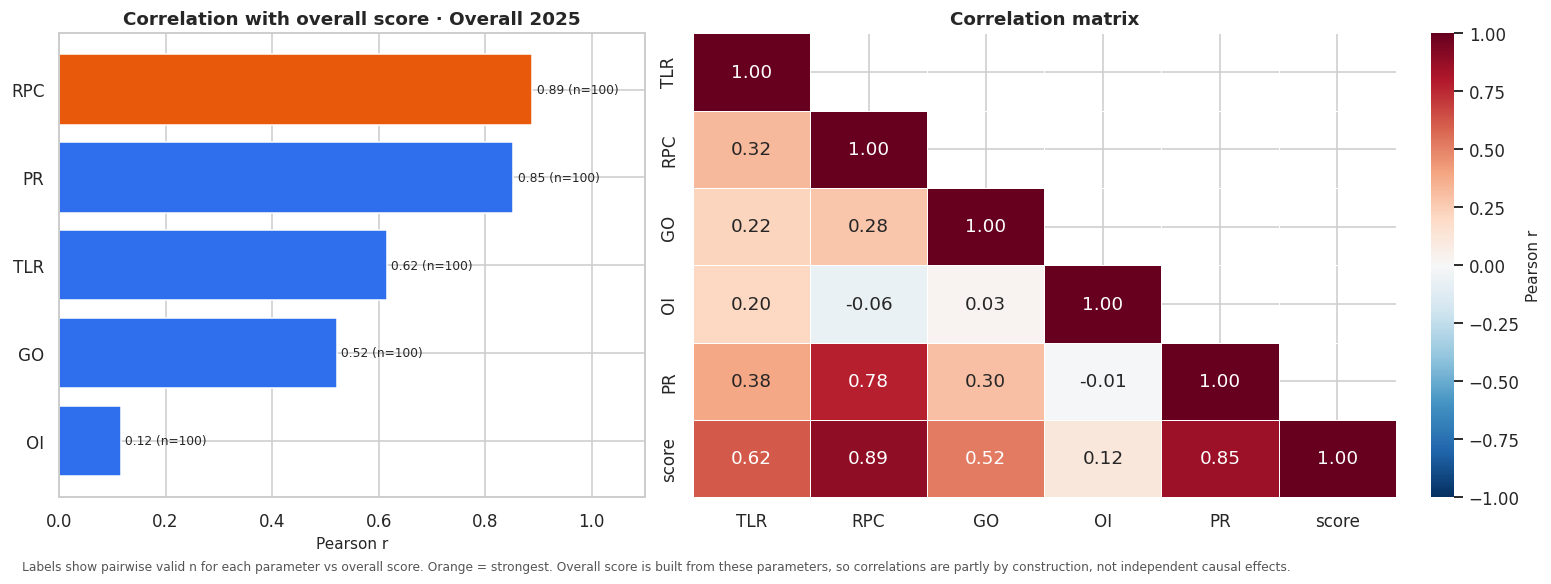

Pairwise valid sample sizes:  {'TLR': 100, 'RPC': 100, 'GO': 100, 'OI': 100, 'PR': 100}


In [15]:
res, _ = S.correlation_with_score(df, CATEGORY, YEAR)
mat, _ = S.correlation_matrix(df, CATEGORY, YEAR)
base = filter_data(df, years=YEAR, category=CATEGORY, require_score=True)
# Pairwise n must use rows with both a parameter value and an overall score.
pair_n = {}
for parameter in res.parameter:
    if parameter in base.columns and "score" in base.columns:
        pair_n[parameter] = int(base[[parameter, "score"]].apply(pd.to_numeric, errors="coerce").dropna().shape[0])
    else:
        pair_n[parameter] = 0
r_ = res.sort_values("pearson_r", ascending=True, na_position="first")  # strongest ends up at the top
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.2]})
bars = axs[0].barh(r_.parameter, r_.pearson_r,
                   color=[PALETTE["accent"] if s else PALETTE["primary"] for s in r_.strongest])
axs[0].bar_label(bars, labels=[f"{v:.2f} (n={pair_n.get(p, 0)})" for p, v in zip(r_.parameter, r_.pearson_r)], padding=3, fontsize=8)
lo = min(0, r_.pearson_r.min())
axs[0].set_xlim(lo - .15 if lo < 0 else 0, min(1.1, r_.pearson_r.max() + .22))
axs[0].set(title=f"Correlation with overall score · {CATEGORY} {YEAR}", xlabel="Pearson r", ylabel="")
M = mat.set_index("variable")
mask = np.triu(np.ones(M.shape, dtype=bool), k=1) if M.shape[0] == M.shape[1] else None
sns.heatmap(M, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=.5, linecolor="white", cbar_kws={"label": "Pearson r"}, ax=axs[1])
axs[1].set(title="Correlation matrix", xlabel="", ylabel="")
caption(fig, "Labels show pairwise valid n for each parameter vs overall score. Orange = strongest. Overall score is built from these parameters, so correlations are partly by construction, not independent causal effects.")
plt.show()
print("Pairwise valid sample sizes: ", pair_n)


### Q4.4  TLR vs RPC

In [ ]:
_ = draw_scatter("TLR", "RPC")
interactive_fig = interactive_scatter("TLR", "RPC")
if interactive_fig is not None:
    interactive_fig.show()


### Q4.5  Has the correlation between research and overall scores changed over time?

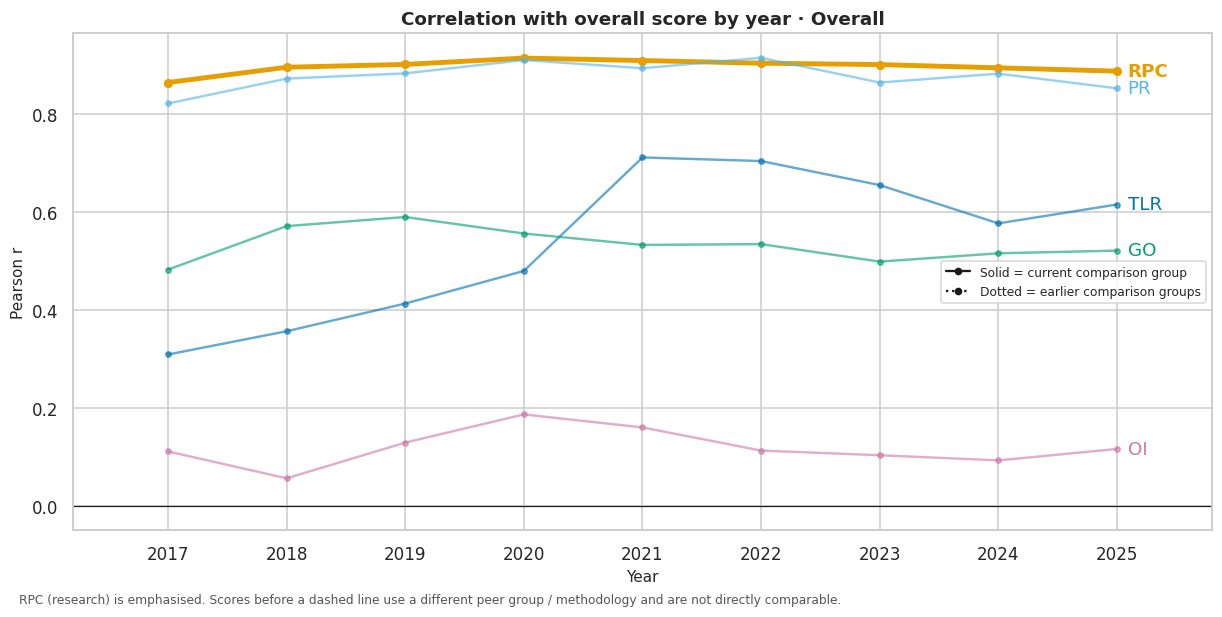

Yearly Pearson correlations:
parameter    GO    OI    PR   RPC   TLR
year                                   
2017       0.48  0.11  0.82  0.86  0.31
2018       0.57  0.06  0.87  0.90  0.36
2019       0.59  0.13  0.88  0.90  0.41
2020       0.56  0.19  0.91  0.91  0.48
2021       0.53  0.16  0.89  0.91  0.71
2022       0.53  0.11  0.92  0.90  0.70
2023       0.50  0.10  0.86  0.90  0.66
2024       0.52  0.09  0.88  0.89  0.58
2025       0.52  0.12  0.85  0.89  0.62

Pairwise valid sample sizes (n):
parameter   GO   OI   PR  RPC  TLR
year                              
2017       100  100  100  100  100
2018       100  100  100  100  100
2019       100  100  100  100  100
2020       101  101  101  101  101
2021       100  100  100  100  100
2022       100  100  100  100  100
2023       100  100  100  100  100
2024       100  100  100  100  100
2025       100  100  100  100  100


In [17]:
res, _ = S.correlation_over_time(df, CATEGORY)
params = [p for p in (PARAMS_SHOWN or list(S.PARAMS)) if p in set(res.parameter)]
last = res.score_comparison_group.iloc[-1]
fig, ax = plt.subplots(figsize=(11, 5.5))
for p in params:
    hi = (p == "RPC"); col = PARAM_COLORS.get(p, PALETTE["neutral"])
    for g, gd in res[res.parameter == p].groupby("score_comparison_group"):
        gd = gd.sort_values("year")
        ax.plot(gd.year, gd.pearson_r, marker="o", ms=5 if hi else 3.5, lw=3.2 if hi else 1.6, alpha=1 if hi else .6,
                color=col, ls="-" if g == last else ":")
    cur = res[(res.parameter == p) & (res.score_comparison_group == last)].sort_values("year")
    if len(cur):
        ax.annotate(p, (cur.year.iloc[-1], cur.pearson_r.iloc[-1]), xytext=(7, 0), textcoords="offset points", va="center",
                    color=col, fontweight="bold" if hi else "normal", annotation_clip=False)
ax.axhline(0, color="k", lw=.8)
mark_group_changes(ax, res); int_years(ax); ax.margins(x=.1)
ax.set_ylim(min(0, res.pearson_r.min()) - .05, min(1.02, res.pearson_r.max() + .05))
ax.legend(handles=LINE_STYLE_HANDLES, fontsize=8, loc="best")
ax.set(title=f"Correlation with overall score by year · {CATEGORY}", xlabel="Year", ylabel="Pearson r")
caption(fig, "RPC (research) is emphasised. " + GROUP_NOTE)
plt.show()
corr_table = res.pivot_table(index="year", columns="parameter", values="pearson_r").round(2)
print("Yearly Pearson correlations:")
print(corr_table.to_string())

# Pairwise sample sizes per year and parameter (both values must be present).
count_rows = []
for yr in sorted(res.year.dropna().unique()):
    yr_df = filter_data(df, years=int(yr), category=CATEGORY, require_score=True)
    for parameter in params:
        n_pair = (yr_df[[parameter, "score"]].apply(pd.to_numeric, errors="coerce").dropna().shape[0]
                  if parameter in yr_df.columns and "score" in yr_df.columns else 0)
        count_rows.append({"year": int(yr), "parameter": parameter, "pairwise_n": int(n_pair)})
count_table = pd.DataFrame(count_rows).pivot(index="year", columns="parameter", values="pairwise_n")
print("\nPairwise valid sample sizes (n):")
print(count_table.to_string())
# The sample-size table is the audit trail for each plotted yearly correlation.

# 5. Interactive scatter visualizations (Plotly)
The Q4.1, Q4.2 and Q4.4 sections now display interactive Plotly scatter plots alongside their static review charts. Hover over a point to see the institution name and paired values. The reusable `interactive_scatter(x, y)` helper can be used for any supported numeric parameter pair. Requires `plotly`.

In [ ]:
# Optional example: change either column name to any supported numeric parameter.
if PLOTLY_OK:
    example_fig = interactive_scatter("RPC", "score")
    if example_fig is not None:
        example_fig.show()
else:
    print("Plotly is not installed - skipping the optional interactive example.")


**Dashboard integration notes:** This notebook embeds a self-contained analysis layer and does not require the team's external `engine` package. For Streamlit, move the shared analysis functions into the project engine and have each analysis function return `(result_df, plotly_figure)`. The Q4.1, Q4.2 and Q4.4 sections include reusable interactive Plotly scatter figures with institution-name tooltips; the remaining charts are currently Matplotlib review charts and should be converted to Plotly for a fully interactive dashboard. The India choropleth requires a verified India state-boundary GeoJSON and reliable state-name mapping. Year, state, category and parameter filters belong in Streamlit widgets. Important data note: missing scores are excluded from score-based calculations; rank-band midpoint values are estimates and are never mixed into the exact-rank histogram.